# Pulseq Import Demo

Generate a Cartesian multi-echo spin-echo `.seq` file, synthesize a small T2 phantom, import the simulated k-space through MRax, and fit a T2 model. The notebook writes temporary artifacts under `tmp/pulseq_t2_notebook`.


## Environment and helpers

The sequence writer uses `pypulseq`, which is installed with MRax. The helper functions below generate a tiny sequence and phantom directly in the notebook so no external data files are needed.


In [ ]:
from pathlib import Path
import json

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from mrax.core.loss_builder import run_fit
from mrax.io import import_pulseq_experiment, read_pulseq, read_pulseq_acquisition
from mrax.reco import reconstruct_acquisition
from mrax.library.default_models import make_t2_se_model
from mrax.reco import fftnc


def _build_t2_phantom(nx: int, ny: int) -> dict[str, jnp.ndarray]:
    xg, yg = jnp.meshgrid(
        jnp.linspace(-1.0, 1.0, nx),
        jnp.linspace(-1.0, 1.0, ny),
        indexing="ij",
    )
    r2 = xg**2 + yg**2
    amplitude = 0.85 + 0.25 * jnp.exp(-2.0 * r2)
    t2 = 35.0 + 55.0 * (0.5 + 0.5 * jnp.cos(np.pi * yg)) * (0.7 + 0.3 * jnp.exp(-1.5 * r2))
    bias = 0.01 * jnp.sin(np.pi * xg) * jnp.cos(np.pi * yg)
    return {
        "amplitude": amplitude.astype(jnp.float32),
        "t2": t2.astype(jnp.float32),
        "bias": bias.astype(jnp.float32),
    }


def write_multi_echo_spin_echo_seq(
    seq_path: Path,
    echo_times_ms: list[float],
    *,
    tr_ms: float,
    matrix_shape: tuple[int, int],
    fov_m: float = 0.20,
    readout_time_ms: float = 3.2,
) -> None:
    try:
        from pypulseq import Opts, Sequence, make_adc, make_block_pulse, make_delay, make_trapezoid
    except ImportError as exc:
        raise RuntimeError("Install MRax with `pip install mrax` to run the Pulseq sequence writer.") from exc

    n_phase, n_read = int(matrix_shape[0]), int(matrix_shape[1])
    system = Opts(
        max_grad=32,
        grad_unit="mT/m",
        max_slew=130,
        slew_unit="T/m/s",
        rf_ringdown_time=20e-6,
        rf_dead_time=100e-6,
        adc_dead_time=20e-6,
    )
    sequence = Sequence(system)
    sequence.set_definition("Name", "t2_mse_cartesian_demo")
    sequence.set_definition("SequenceName", "mse")
    sequence.set_definition("ProtocolName", "pulseq_t2_cartesian_demo")
    sequence.set_definition("TE", [float(te) for te in echo_times_ms])
    sequence.set_definition("TR", float(tr_ms))
    sequence.set_definition("Matrix", [n_read, n_phase])
    sequence.set_definition("FOV", [float(fov_m), float(fov_m)])

    rf90 = make_block_pulse(
        flip_angle=np.pi / 2.0,
        duration=1e-3,
        delay=system.rf_dead_time,
        system=system,
        use="excitation",
    )
    rf180 = make_block_pulse(
        flip_angle=np.pi,
        duration=1e-3,
        delay=system.rf_dead_time,
        system=system,
        use="refocusing",
    )

    delta_k = 1.0 / float(fov_m)
    readout_width = n_read * delta_k
    readout = make_trapezoid(
        channel="x",
        flat_area=readout_width,
        flat_time=float(readout_time_ms) * 1e-3,
        system=system,
    )
    adc = make_adc(
        num_samples=n_read,
        duration=readout.flat_time,
        delay=readout.rise_time + system.adc_dead_time,
        system=system,
    )
    readout_prephaser = make_trapezoid(channel="x", area=-0.5 * readout_width, duration=1e-3, system=system)
    readout_rewinder = make_trapezoid(channel="x", area=-0.5 * readout_width, duration=1e-3, system=system)
    pre_readout_duration = (
        readout_prephaser.delay
        + readout_prephaser.rise_time
        + readout_prephaser.flat_time
        + readout_prephaser.fall_time
    )
    readout_duration = readout.delay + readout.rise_time + readout.flat_time + readout.fall_time
    ky_values = (np.arange(n_phase) - 0.5 * (n_phase - 1)) * delta_k

    for te_ms in echo_times_ms:
        te_s = float(te_ms) * 1e-3
        if te_s <= 5e-3:
            raise ValueError("Echo times must exceed the RF and gradient block durations.")

        rf_center_delay = max(te_s / 2.0 - rf90.shape_dur / 2.0 - rf180.shape_dur / 2.0, 1e-4)
        readout_center_delay = max(
            te_s / 2.0 - rf180.shape_dur / 2.0 - 0.5 * (pre_readout_duration + readout_duration),
            1e-4,
        )

        for ky in ky_values:
            phase_prephaser = make_trapezoid(channel="y", area=float(ky), duration=1e-3, system=system)
            phase_rewinder = make_trapezoid(channel="y", area=float(-ky), duration=1e-3, system=system)
            sequence.add_block(rf90)
            sequence.add_block(make_delay(rf_center_delay))
            sequence.add_block(rf180)
            sequence.add_block(make_delay(readout_center_delay))
            sequence.add_block(readout_prephaser, phase_prephaser)
            sequence.add_block(readout, adc)
            sequence.add_block(readout_rewinder, phase_rewinder)
            recovery_delay = max(float(tr_ms) * 1e-3 - te_s - 10e-3, 1e-4)
            sequence.add_block(make_delay(recovery_delay))

    seq_path.parent.mkdir(parents=True, exist_ok=True)
    sequence.write(str(seq_path))


def simulate_t2_images_from_seq(
    seq_path: Path,
    phantom_fields: dict[str, jnp.ndarray],
    *,
    noise_std: float,
    seed: int,
) -> tuple[np.ndarray, np.ndarray]:
    info = read_pulseq(seq_path)
    echo_times = np.asarray(info.normalized_metadata.echo_times, dtype=np.float32)
    if echo_times.ndim == 0:
        echo_times = echo_times[None]
    if echo_times.size == 0:
        raise ValueError("Pulseq sequence did not provide echo times for T2 simulation.")

    model = make_t2_se_model(scale=1.0)
    clean = model.model_apply(
        phantom_fields,
        None,
        {"TE": jnp.asarray(echo_times, dtype=jnp.float32)},
        _allow_direct=True,
    )
    rng = np.random.default_rng(seed)
    noisy = np.asarray(clean) + noise_std * rng.standard_normal(np.asarray(clean).shape).astype(np.float32)
    return noisy.astype(np.float32), echo_times


def simulate_t2_kspace(images: np.ndarray) -> np.ndarray:
    return np.asarray(fftnc(np.asarray(images), axes=(-2, -1)), dtype=np.complex64)


plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


## Generate a Cartesian Pulseq sequence

The helper below writes a line-readout spin-echo sequence with one full Cartesian readout per phase-encoding line and one complete k-space traversal per echo time. The important definitions for MRax are `TE`, `TR`, `Matrix`, and `FOV`.


In [2]:
output_dir = Path.cwd() / 'tmp' / 'pulseq_t2_notebook'
output_dir.mkdir(parents=True, exist_ok=True)
seq_path = output_dir / 't2_mapping_demo.seq'

nx = 20
ny = 20
echo_times_ms = [12.0, 24.0, 36.0, 48.0, 72.0, 96.0]
tr_ms = 1500.0

write_multi_echo_spin_echo_seq(
    seq_path,
    echo_times_ms,
    tr_ms=tr_ms,
    matrix_shape=(nx, ny),
)

info = read_pulseq(seq_path)
print(json.dumps({
    'sequence_kind': info.sequence_kind,
    'spatial_shape': info.spatial_shape,
    'adc_counts_head': list(info.adc_counts[:4]),
    'echo_times_ms': list(np.asarray(info.normalized_metadata.echo_times, dtype=float)),
}, indent=2))


{
  "sequence_kind": "cartesian",
  "spatial_shape": [
    20,
    20
  ],
  "adc_counts_head": [
    20,
    20,
    20,
    20
  ],
  "echo_times_ms": [
    12.0,
    24.0,
    36.0,
    48.0,
    72.0,
    96.0
  ]
}


## Build a synthetic T2 phantom and simulate k-space

The signal model uses the `TE` values parsed from the `.seq` file, so the import path and the simulation path stay aligned. The images are transformed to Cartesian k-space with the centered FFT helper from MRax.


In [3]:
truth = _build_t2_phantom(nx, ny)
truth_images, echo_times_from_seq = simulate_t2_images_from_seq(
    seq_path,
    truth,
    noise_std=0.01,
    seed=0,
)
kspace = simulate_t2_kspace(truth_images)

print(
    f"images shape={truth_images.shape}, kspace shape={kspace.shape}, "
    f"echoes={echo_times_from_seq.tolist()}"
)


images shape=(6, 20, 20), kspace shape=(6, 20, 20), echoes=[12.0, 24.0, 36.0, 48.0, 72.0, 96.0]


## Import the experiment through `kspace=` and fit the T2 model

Here the Pulseq importer uses the sequence definitions and ADC trajectory to classify the acquisition as Cartesian. Because the dataset is imported from k-space only, the preview image in `DataSet.data` is reconstructed internally with the standard Cartesian inverse FFT.


In [ ]:
acquisition = read_pulseq_acquisition(seq_path, kspace, spatial_shape=(nx, ny))
image = reconstruct_acquisition(acquisition).image
experiment, dataset, model, metadata = import_pulseq_experiment(
    seq_path,
    kspace=kspace, image_data=image,
    spatial_shape=(nx, ny),
    model_map_by_type={'mse': lambda: make_t2_se_model(scale=1.0)},
)

fitted_fields, losses = run_fit(
    experiment,
    model,
    dataset,
    num_steps=250,
    step_size=0.05,
)

summary = {
    'exp_type': experiment.exp_type,
    'sequence_kind': metadata['pulseq']['sequence_kind'],
    'imported_te_ms': list(np.asarray(experiment.observables['TE'].values, dtype=float)),
    'recon_rmse': float(np.sqrt(np.mean((np.asarray(dataset.data) - truth_images) ** 2))),
    't2_rmse_ms': float(np.sqrt(np.mean((np.asarray(fitted_fields['t2']) - np.asarray(truth['t2'])) ** 2))),
    'final_loss': float(losses[-1]),
}
summary


## Visualize k-space, imported images, and fitted maps

The first row shows representative k-space magnitudes for early, middle, and late echoes. The second row shows the reconstructed image stack imported by MRax. The last two rows compare the ground-truth and fitted parameter maps.


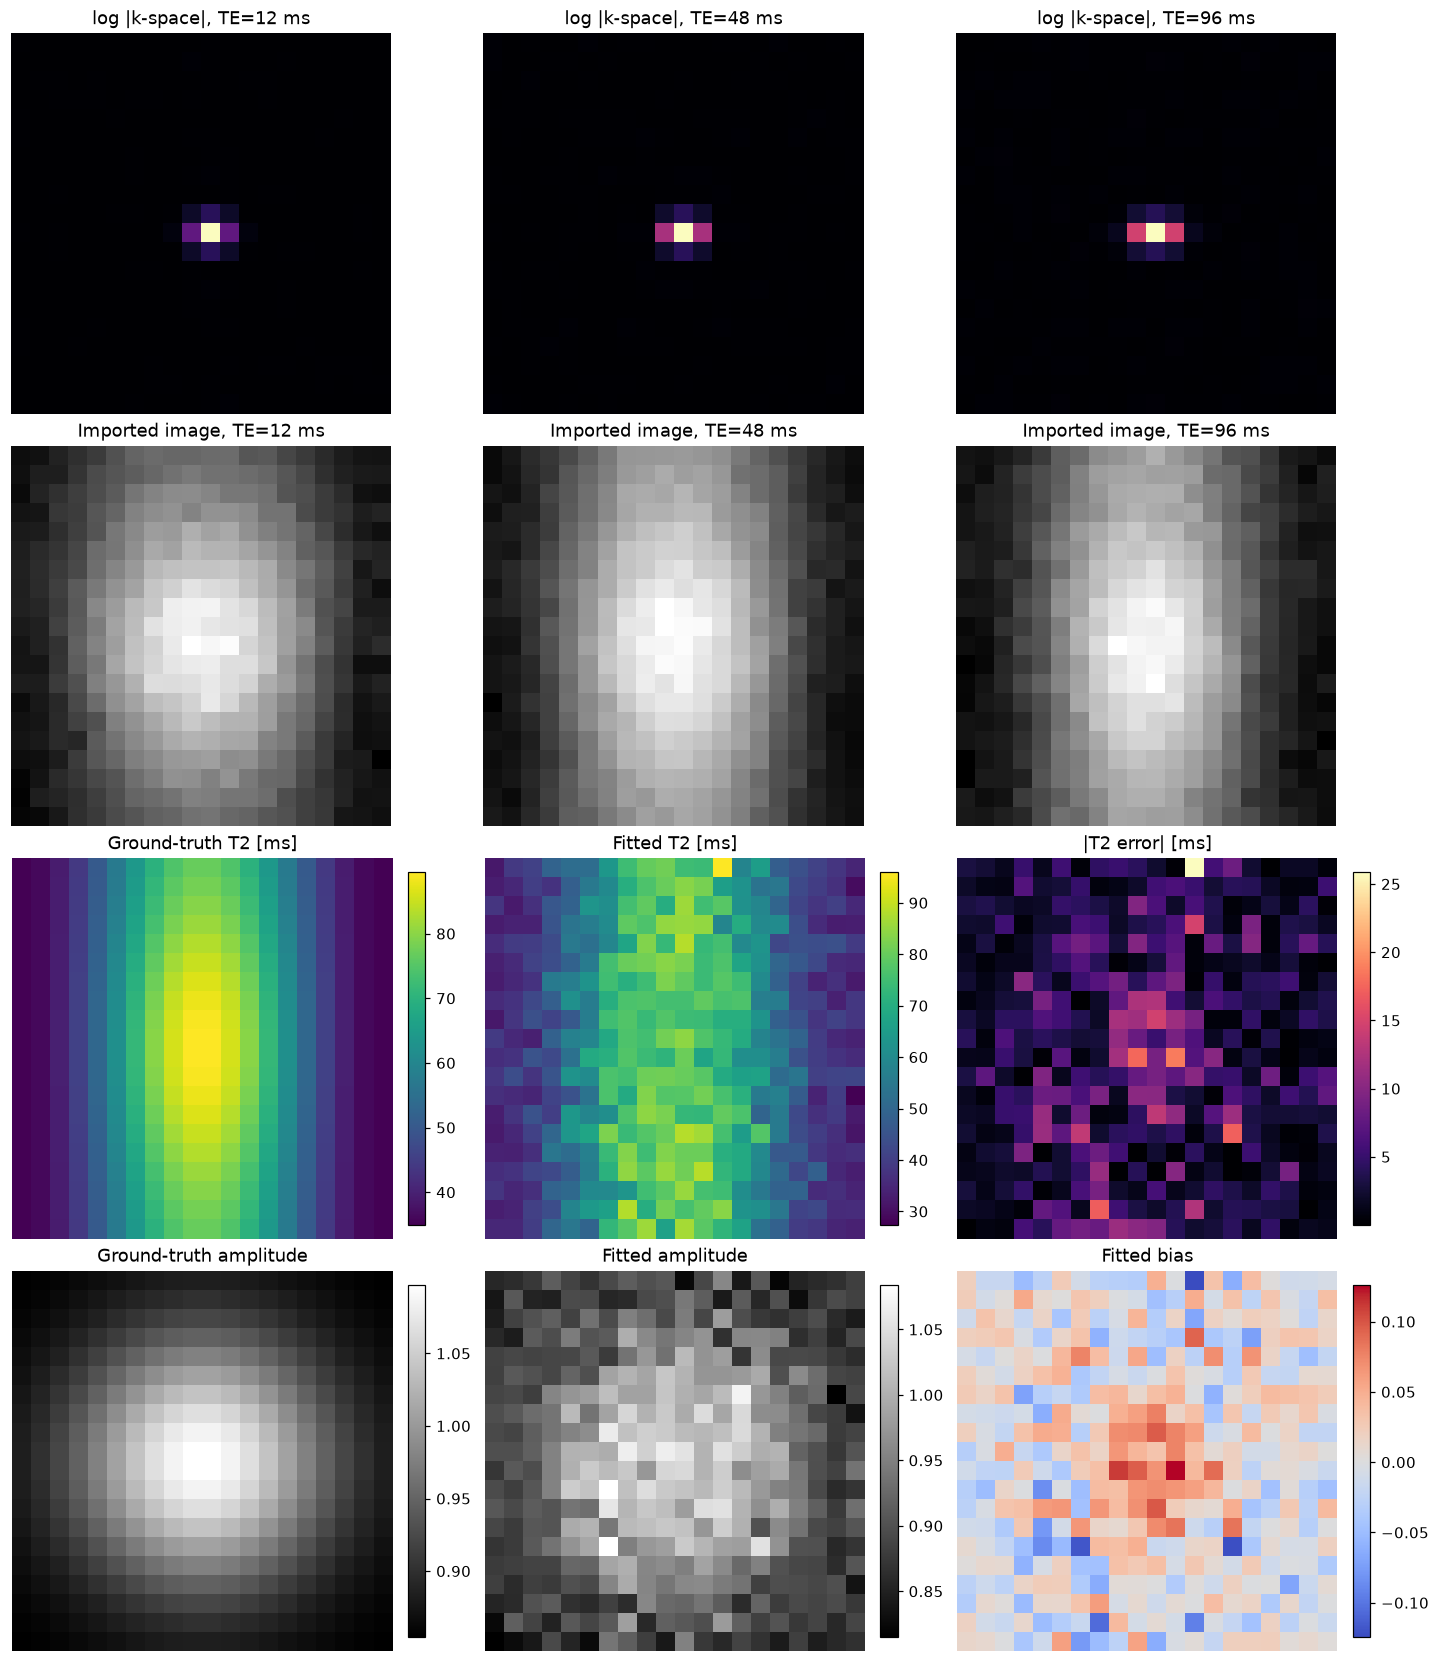

Saved overview figure to tmp/pulseq_t2_notebook/pulseq_import_demo_overview.png


In [5]:
imported_images = np.asarray(dataset.data, dtype=np.float32)
imported_kspace = np.asarray(dataset.kspace, dtype=np.complex64)[:, 0]  # single receiver
truth_t2 = np.asarray(truth["t2"], dtype=np.float32)
truth_amp = np.asarray(truth["amplitude"], dtype=np.float32)
fit_t2 = np.asarray(fitted_fields["t2"], dtype=np.float32)
fit_amp = np.asarray(fitted_fields["amplitude"], dtype=np.float32)
fit_bias = np.asarray(fitted_fields["bias"], dtype=np.float32)

frame_indices = [0, len(echo_times_from_seq) // 2, len(echo_times_from_seq) - 1]
fig, axes = plt.subplots(4, 3, figsize=(13, 15), constrained_layout=True)

for col, frame_idx in enumerate(frame_indices):
    axes[0, col].imshow(np.log1p(np.abs(imported_kspace[frame_idx])), cmap="magma")
    axes[0, col].set_title(f"log |k-space|, TE={echo_times_from_seq[frame_idx]:.0f} ms")
    axes[0, col].axis("off")

    axes[1, col].imshow(imported_images[frame_idx], cmap="gray")
    axes[1, col].set_title(f"Imported image, TE={echo_times_from_seq[frame_idx]:.0f} ms")
    axes[1, col].axis("off")

map_specs = [
    (truth_t2, "Ground-truth T2 [ms]", "viridis"),
    (fit_t2, "Fitted T2 [ms]", "viridis"),
    (np.abs(fit_t2 - truth_t2), "|T2 error| [ms]", "magma"),
    (truth_amp, "Ground-truth amplitude", "gray"),
    (fit_amp, "Fitted amplitude", "gray"),
    (fit_bias, "Fitted bias", "coolwarm"),
]

for panel_idx, (image, title, cmap) in enumerate(map_specs):
    row = 2 + panel_idx // 3
    col = panel_idx % 3
    artist = axes[row, col].imshow(image, cmap=cmap)
    axes[row, col].set_title(title)
    axes[row, col].axis("off")
    fig.colorbar(artist, ax=axes[row, col], fraction=0.046, pad=0.04)

figure_path = output_dir / "pulseq_import_demo_overview.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved overview figure to {figure_path}")


## Save a compact result bundle

The notebook keeps the same artifact pattern as the script so the outputs can be inspected outside Jupyter as well.


In [6]:
np.savez_compressed(
    output_dir / 'pulseq_import_demo_results.npz',
    kspace=imported_kspace,
    images=imported_images,
    echo_times_ms=np.asarray(echo_times_from_seq, dtype=np.float32),
    truth_amplitude=truth_amp,
    truth_t2=truth_t2,
    fit_amplitude=fit_amp,
    fit_t2=fit_t2,
    fit_bias=fit_bias,
    losses=np.asarray(losses, dtype=np.float32),
)

with (output_dir / 'pulseq_import_demo_summary.json').open('w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2)

print(output_dir)


tmp/pulseq_t2_notebook
